<a href="https://colab.research.google.com/github/rutuja2005byte/Monte-Carlo-Portfolio-Risk-Simulator/blob/main/Monte_Carlo_Portfolio_Risk_Simulator.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
np.random.seed(42)

num_simulations = 10_000
trading_days = 252
initial_investment = 100_000

asset_names = ["Stocks", "Bonds", "Gold", "Cash"]

annual_mean = np.array([0.08, 0.04, 0.06, 0.03])
annual_volatility = np.array([0.20, 0.08, 0.15, 0.01])

daily_mean = annual_mean / trading_days
daily_volatility = annual_volatility / np.sqrt(trading_days)


weights = np.array([0.25, 0.25, 0.25, 0.25])

print("Simulations:", num_simulations)
print("Trading days:", trading_days)
print("Initial investment: ₹", initial_investment)
print("Assets:", asset_names)
print("Daily mean returns:", daily_mean)
print("Daily volatility:", daily_volatility)
print("Portfolio weights:", weights)


Simulations: 10000
Trading days: 252
Initial investment: ₹ 100000
Assets: ['Stocks', 'Bonds', 'Gold', 'Cash']
Daily mean returns: [0.00031746 0.00015873 0.0002381  0.00011905]
Daily volatility: [0.01259882 0.00503953 0.00944911 0.00062994]
Portfolio weights: [0.25 0.25 0.25 0.25]


In [4]:
simulated_returns = np.random.normal(
    loc=daily_mean,
    scale=daily_volatility,
    size=(num_simulations, trading_days, len(asset_names))
)

print("Shape:", simulated_returns.shape)
print("Data type:", simulated_returns.dtype)
print("First simulation, first day:", simulated_returns[0, 0])
print("First simulation, all days:", simulated_returns[0].shape)



Shape: (10000, 252, 4)
Data type: float64
First simulation, first day: [ 1.32768091e-03 -7.32971121e-03  7.82317946e-03  2.45989751e-05]
First simulation, all days: (252, 4)


In [5]:
portfolio_returns = simulated_returns @ weights

log_returns = np.log1p(portfolio_returns)

cumulative_growth = np.exp(np.cumsum(log_returns, axis=1))

portfolio_paths = initial_investment * cumulative_growth

portfolio_paths = np.column_stack([
    np.full(num_simulations, initial_investment),
    portfolio_paths
])

print("Portfolio paths shape:", portfolio_paths.shape)
print("First simulation, initial value:", portfolio_paths[0, 0])
print("First simulation, final value: ₹", round(portfolio_paths[0, -1], 2))


Portfolio paths shape: (10000, 253)
First simulation, initial value: 100000.0
First simulation, final value: ₹ 106995.45


Initial investment: ₹ 100000
Mean final value: ₹ 105433.87
Median final value: ₹ 105178.16
Annualized volatility: 6.57 %
95% VaR: ₹ 5597.1
Probability of ending with a loss: 22.22 %


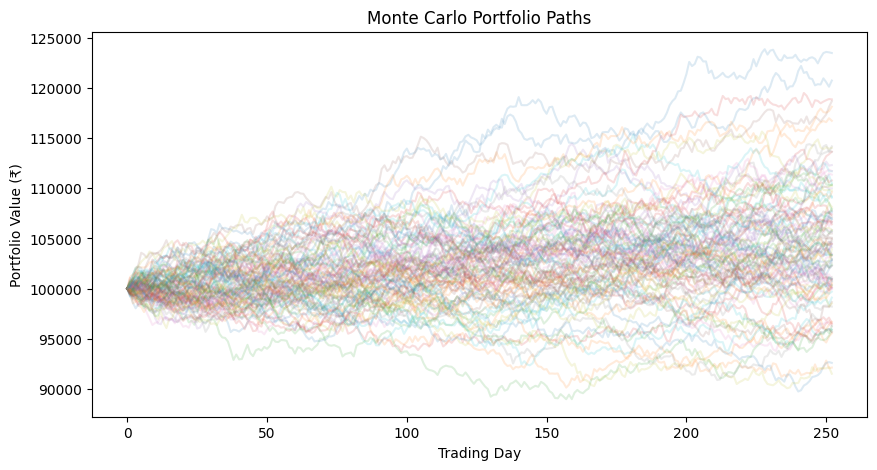

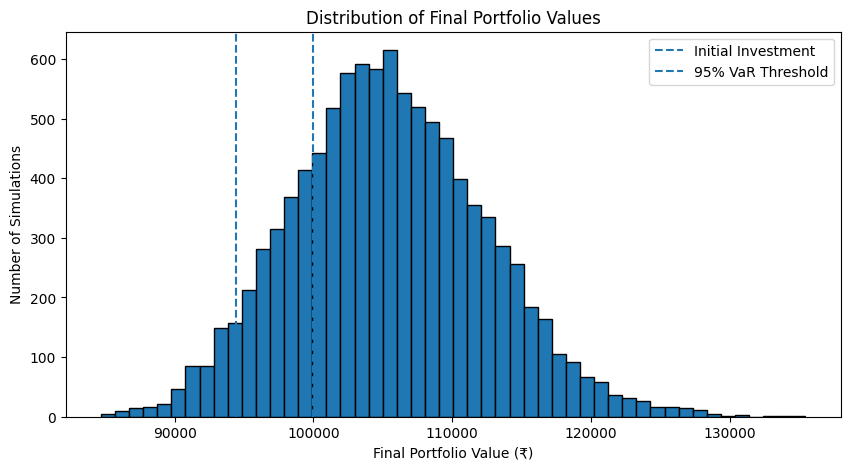

In [6]:
final_values = portfolio_paths[:, -1]

daily_portfolio_returns = portfolio_paths[:, 1:] / portfolio_paths[:, :-1] - 1

daily_vol = np.std(daily_portfolio_returns)
annualized_volatility = daily_vol * np.sqrt(trading_days)

losses = initial_investment - final_values
var_95 = np.percentile(losses, 95)

loss_probability = np.mean(final_values < initial_investment) * 100

print("Initial investment: ₹", initial_investment)
print("Mean final value: ₹", round(np.mean(final_values), 2))
print("Median final value: ₹", round(np.median(final_values), 2))
print("Annualized volatility:", round(annualized_volatility * 100, 2), "%")
print("95% VaR: ₹", round(var_95, 2))
print("Probability of ending with a loss:", round(loss_probability, 2), "%")


plt.figure(figsize=(10, 5))
plt.plot(portfolio_paths[:100].T, alpha=0.15)
plt.title("Monte Carlo Portfolio Paths")
plt.xlabel("Trading Day")
plt.ylabel("Portfolio Value (₹)")
plt.show()


plt.figure(figsize=(10, 5))
plt.hist(final_values, bins=50, edgecolor="black")
plt.axvline(initial_investment, linestyle="--", label="Initial Investment")
plt.axvline(initial_investment - var_95, linestyle="--", label="95% VaR Threshold")
plt.title("Distribution of Final Portfolio Values")
plt.xlabel("Final Portfolio Value (₹)")
plt.ylabel("Number of Simulations")
plt.legend()
plt.show()
